In [2]:
!pip install pandas numpy scikit-learn matplotlib seaborn nltk

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import pandas as pd

df = pd.read_csv("../dataset/processed/CLEANED-FINAL.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (28332, 8)

Available columns:
['review_title', 'review_text', 'combined_text_no_rating', 'final_model_text_no_rating', 'rating', 'product_name', 'brand', 'category']
Dataset loaded successfully!
Shape: (28332, 8)


In [5]:
reviews = df["final_model_text_no_rating"].fillna("")

reviews = reviews.astype(str)

# Remove empty reviews
reviews = reviews[reviews.str.strip() != ""]

print("Total usable reviews:", len(reviews))
print(reviews.head())

Total usable reviews: 28311
0    order 3 one item bad quality miss backup sprin...
1       bulk always less expensive way go product like
2                        well not duracell price happy
3    well name brand battery much well seem work we...
4                     battery long lasting price great
Name: final_model_text_no_rating, dtype: str


In [6]:
print("Missing values:", reviews.isnull().sum())
print("Empty reviews:", (reviews.str.strip() == "").sum())

Missing values: 0
Empty reviews: 0


In [7]:
# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

# Convert reviews into numerical features
X_tfidf = tfidf.fit_transform(reviews)

# Display results
print("TF-IDF Vectorization Completed!")
print("TF-IDF Matrix Shape:", X_tfidf.shape)

print("\nTotal Features:", len(tfidf.get_feature_names_out()))

print("\nSample Features:")
print(tfidf.get_feature_names_out()[:20])

TF-IDF Vectorization Completed!
TF-IDF Matrix Shape: (28311, 5000)

Total Features: 5000

Sample Features:
['00' '10' '10 year' '100' '11' '11 year' '12' '12 year' '128' '128 gb'
 '128gb' '13' '15' '16' '16 gb' '16gb' '17' '18' '18 month' '1st']


In [8]:
# Initialize Truncated SVD
svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

# Reduce TF-IDF dimensions
X_svd = svd.fit_transform(X_tfidf)

# Display results
print("Truncated SVD Completed!")

print("Original TF-IDF Shape:", X_tfidf.shape)

print("Reduced SVD Shape:", X_svd.shape)

print(
    "Total Explained Variance:",
    svd.explained_variance_ratio_.sum()
)

Truncated SVD Completed!
Original TF-IDF Shape: (28311, 5000)
Reduced SVD Shape: (28311, 100)
Total Explained Variance: 0.2977900458684149


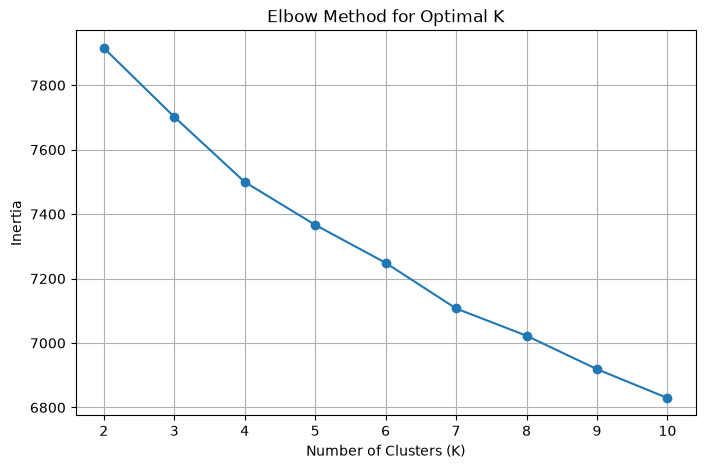

In [9]:
inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_svd)
    inertia_values.append(kmeans.inertia_)

# Plot Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [20]:
for k, inertia in zip(k_values, inertia_values):
    print(f"K = {k}, Inertia = {inertia:.2f}")

K = 2, Inertia = 7915.57
K = 3, Inertia = 7701.92
K = 4, Inertia = 7499.79
K = 5, Inertia = 7366.73
K = 6, Inertia = 7248.86
K = 7, Inertia = 7107.23
K = 8, Inertia = 7022.66
K = 9, Inertia = 6918.80
K = 10, Inertia = 6829.40


In [10]:
silhouette_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_svd)

    score = silhouette_score(
        X_svd,
        labels,
        sample_size=5000,
        random_state=42
    )

    silhouette_values.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.0699
K = 3, Silhouette Score = 0.0695
K = 4, Silhouette Score = 0.0506
K = 5, Silhouette Score = 0.0243
K = 6, Silhouette Score = 0.0594
K = 7, Silhouette Score = 0.0380
K = 8, Silhouette Score = 0.0387
K = 9, Silhouette Score = 0.0441
K = 10, Silhouette Score = 0.0500


In [11]:
feature_names = tfidf.get_feature_names_out()

for k in [3, 4]:

    print(f"\n========== K = {k} ==========")

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_svd)

    for cluster in range(k):

        cluster_indices = np.where(labels == cluster)[0]

        # Calculate cluster size
        print(f"\nCluster {cluster}")
        print("Number of reviews:", len(cluster_indices))

        # Find the most important terms
        cluster_tfidf = X_tfidf[cluster_indices]
        mean_tfidf = np.asarray(
            cluster_tfidf.mean(axis=0)
        ).flatten()

        top_indices = mean_tfidf.argsort()[-10:][::-1]
        top_terms = feature_names[top_indices]

        print("Top terms:", ", ".join(top_terms))


========== K = 3 ==========

Cluster 0
Number of reviews: 1828
Top terms: good, good price, price, good battery, battery, good value, value, good product, battery good, good deal

Cluster 1
Number of reviews: 8107
Top terms: battery, great, work, price, last, long, brand, great price, last long, well

Cluster 2
Number of reviews: 18376
Top terms: tablet, great, love, kid, use, buy, easy, kindle, product, good

========== K = 4 ==========

Cluster 0
Number of reviews: 6699
Top terms: battery, work, last, long, brand, last long, well, name, good, price

Cluster 1
Number of reviews: 2080
Top terms: great, great price, price, value, great value, work great, work, battery, great battery, great product

Cluster 2
Number of reviews: 17871
Top terms: tablet, great, love, kid, use, easy, buy, kindle, good, old

Cluster 3
Number of reviews: 1661
Top terms: good, good price, price, good battery, battery, good value, value, good product, battery good, good deal


In [21]:
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

labels_4 = kmeans_4.fit_predict(X_svd)

for cluster in range(4):
    indices = np.where(labels_4 == cluster)[0]

    cluster_tfidf = X_tfidf[indices]
    mean_tfidf = np.asarray(cluster_tfidf.mean(axis=0)).flatten()

    top_indices = mean_tfidf.argsort()[-10:][::-1]
    top_terms = feature_names[top_indices]

    print(f"\nCluster {cluster}")
    print("Reviews:", len(indices))
    print("Top terms:", ", ".join(top_terms))


Cluster 0
Reviews: 6699
Top terms: battery, work, last, long, brand, last long, well, name, good, price

Cluster 1
Reviews: 2080
Top terms: great, great price, price, value, great value, work great, work, battery, great battery, great product

Cluster 2
Reviews: 17871
Top terms: tablet, great, love, kid, use, easy, buy, kindle, good, old

Cluster 3
Reviews: 1661
Top terms: good, good price, price, good battery, battery, good value, value, good product, battery good, good deal


In [12]:
# Apply K-Means with K = 4
final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(X_svd)

# Calculate distance from each review to its cluster centre
distances = final_kmeans.transform(X_svd)

for cluster in range(4):

    print(f"\n========== CLUSTER {cluster} ==========")

    # Find reviews belonging to this cluster
    indices = np.where(final_labels == cluster)[0]

    # Get distances to this cluster's centroid
    cluster_distances = distances[indices, cluster]

    # Find 5 closest reviews
    closest_indices = indices[
        np.argsort(cluster_distances)[:5]
    ]

    for i, idx in enumerate(closest_indices, 1):
        print(f"\nReview {i}:")
        print(reviews.iloc[idx])


========== CLUSTER 0 ==========

Review 1:
disappointed battery notably less long live compare brand disappoint

Review 2:
2 way radio drain battery daily expensive

Review 3:
half battery won't recharge throw away

Review 4:
half battery won't recharge throw away

Review 5:
truly disappointed battery

========== CLUSTER 1 ==========

Review 1:
value great price haven't compare side side battery haven't notice differents performance

Review 2:
great price god batteries bulk

Review 3:
wonderful great

Review 4:
wonderful great

Review 5:
great transaction receive promised

========== CLUSTER 2 ==========

Review 1:
dy easily

Review 2:
great door prize give door prize office party love

Review 3:
must someone talk answer

Review 4:
let 5 recharges

Review 5:
cool awsome

========== CLUSTER 3 ==========

Review 1:
real good

Review 2:
real good tuff

Review 3:
good costco

Review 4:
good duracells

Review 5:
good duracells


In [13]:
for cluster in range(4):

    print(f"\n========== CLUSTER {cluster} ==========")

    indices = np.where(final_labels == cluster)[0]

    cluster_distances = distances[indices, cluster]

    closest_indices = indices[
        np.argsort(cluster_distances)[:5]
    ]

    for i, idx in enumerate(closest_indices, 1):

        print(f"\nReview {i}")

        print("Processed Review:")
        print(reviews.iloc[idx])

        print("\nOriginal Review:")
        print(df.loc[reviews.index[idx], "review_text"])

        print("-" * 60)


========== CLUSTER 0 ==========

Review 1
Processed Review:
disappointed battery notably less long live compare brand disappoint

Original Review:
Batteries are notably less long-lived compared to other brands. Disappointed!
------------------------------------------------------------

Review 2
Processed Review:
2 way radio drain battery daily expensive

Original Review:
2 way radio drained batteries daily so too expensive
------------------------------------------------------------

Review 3
Processed Review:
half battery won't recharge throw away

Original Review:
About half of the batteries won't recharge, so I threw them away
------------------------------------------------------------

Review 4
Processed Review:
half battery won't recharge throw away

Original Review:
About half of the batteries won't recharge, so I threw them away
------------------------------------------------------------

Review 5
Processed Review:
truly disappointed battery

Original Review:
I'm truly disapp

In [14]:
kmeans_5 = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

labels_5 = kmeans_5.fit_predict(X_svd)

for cluster in range(5):

    indices = np.where(labels_5 == cluster)[0]

    print(f"\n========== CLUSTER {cluster} ==========")
    print("Number of reviews:", len(indices))

    cluster_tfidf = X_tfidf[indices]

    mean_tfidf = np.asarray(
        cluster_tfidf.mean(axis=0)
    ).flatten()

    top_indices = mean_tfidf.argsort()[-10:][::-1]

    print(
        "Top terms:",
        ", ".join(feature_names[top_indices])
    )


========== CLUSTER 0 ==========
Number of reviews: 13193
Top terms: love, great, kindle, use, buy, product, good, easy, work, not

========== CLUSTER 1 ==========
Number of reviews: 6087
Top terms: battery, last, long, work, brand, last long, name, well, good, price

========== CLUSTER 2 ==========
Number of reviews: 5575
Top terms: tablet, great, kid, great tablet, love, use, old, year, easy, year old

========== CLUSTER 3 ==========
Number of reviews: 1568
Top terms: good, good price, price, good battery, battery, good value, value, battery good, good deal, good product

========== CLUSTER 4 ==========
Number of reviews: 1888
Top terms: great, great price, price, great value, work great, value, work, battery, great battery, great product


In [15]:
distances_5 = kmeans_5.transform(X_svd)

for cluster in range(5):

    print(f"\n========== CLUSTER {cluster} ==========")

    indices = np.where(labels_5 == cluster)[0]

    cluster_distances = distances_5[indices, cluster]

    closest_indices = indices[
        np.argsort(cluster_distances)[:5]
    ]

    for i, idx in enumerate(closest_indices, 1):

        print(f"\nReview {i}:")
        print(df.loc[reviews.index[idx], "review_text"])


========== CLUSTER 0 ==========

Review 1:
With this you have someone to talk to and answers you.

Review 2:
Awsome ................ ....................... ...

Review 3:
WORD!!

Review 4:
Bought for me.

Review 5:
Yes It is as ecpected

========== CLUSTER 1 ==========

Review 1:
Batteries are notably less long-lived compared to other brands. Disappointed!

Review 2:
2 way radio drained batteries daily so too expensive

Review 3:
I'm truly disappointed with these batteries

Review 4:
About half of the batteries won't recharge, so I threw them away

Review 5:
About half of the batteries won't recharge, so I threw them away

========== CLUSTER 2 ==========

Review 1:
Great entry level tablet for kids without the worries of easy breakage.

Review 2:
This product is a great learning tool for my 4yr old toddler. It's has the option for kid mode or regular tablet mode.

Review 3:
This product is a great learning tool for my 4yr old toddler. It's has the option for kid mode or regular table

In [16]:
for cluster in range(5):

    print(f"\n========== CLUSTER {cluster} ==========")

    cluster_df = df.loc[
        reviews.index[labels_5 == cluster]
    ]

    print(
        cluster_df["category"]
        .value_counts()
        .head(5)
    )


========== CLUSTER 0 ==========
category
AA,AAA,Health,Electronics,Health & Household,Camcorder Batteries,Camera & Photo,Batteries,Household Batteries,Robot Check,Accessories,Camera Batteries,Health and Beauty,Household Supplies,Batteries & Chargers,Health, Household & Baby Care,Health Personal Care             2148
Fire Tablets,Tablets,All Tablets,Amazon Tablets,Genuine Tablet Accessories,Computers & Tablets,Electronics,Amazon                                                                                                                                                               1534
Fire Tablets,Computers/Tablets & Networking,Electronics Features,Tablets,All Tablets,Amazon Tablets,Computers & Tablets,Electronics,iPad & Tablets,Tablets & eBook Readers                                                                                                      1515
Fire Tablets,Tablets,All Tablets,Amazon Tablets,Computers & Tablets                                                            

In [17]:
# Initialize PCA
pca = PCA(n_components=2, random_state=42)

# Transform the 100-dimensional data into 2 dimensions
X_pca = pca.fit_transform(X_svd)

print("PCA Completed!")
print("Original Shape:", X_svd.shape)
print("Reduced Shape:", X_pca.shape)

print(
    "Explained Variance:",
    pca.explained_variance_ratio_.sum()
)

PCA Completed!
Original Shape: (28311, 100)
Reduced Shape: (28311, 2)
Explained Variance: 0.09851057227204252


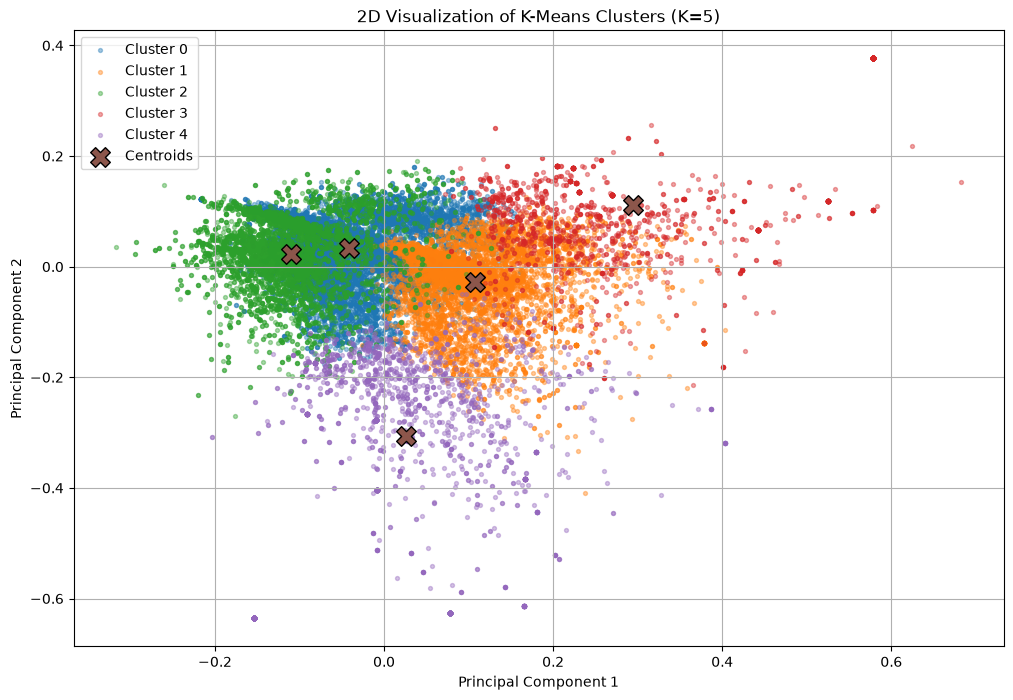

In [18]:
plt.figure(figsize=(12, 8))

for cluster in range(5):
    cluster_points = X_pca[labels_5 == cluster]

    plt.scatter(
        cluster_points[:, 0],
        cluster_points[:, 1],
        s=8,
        alpha=0.4,
        label=f"Cluster {cluster}"
    )

# Project cluster centroids into 2D
centroids_2d = pca.transform(kmeans_5.cluster_centers_)

plt.scatter(
    centroids_2d[:, 0],
    centroids_2d[:, 1],
    marker='X',
    s=200,
    edgecolors='black',
    label='Centroids'
)

plt.title("2D Visualization of K-Means Clusters (K=5)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
reviews = df["final_model_text_no_rating"].fillna("")
reviews = reviews.astype(str)

# Remove empty reviews
reviews = reviews[reviews.str.strip() != ""]

print("Total valid reviews:", len(reviews))
print("\nSample reviews:")
print(reviews.head())

Total valid reviews: 28311

Sample reviews:
0    order 3 one item bad quality miss backup sprin...
1       bulk always less expensive way go product like
2                        well not duracell price happy
3    well name brand battery much well seem work we...
4                     battery long lasting price great
Name: final_model_text_no_rating, dtype: str


In [22]:
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels_3 = kmeans_3.fit_predict(X_svd)

distances = kmeans_3.transform(X_svd)

for cluster in range(3):
    print(f"\n========== CLUSTER {cluster} ==========")

    cluster_indices = np.where(labels_3 == cluster)[0]

    closest_indices = cluster_indices[
        np.argsort(distances[cluster_indices, cluster])[:5]
    ]

    for idx in closest_indices:
        print("\nReview:", reviews.iloc[idx])


========== CLUSTER 0 ==========

Review: good costco

Review: real good

Review: real good tuff

Review: good duracells

Review: good duracells

========== CLUSTER 1 ==========

Review: great supply battery especially

Review: disappointed battery notably less long live compare brand disappoint

Review: half battery won't recharge throw away

Review: half battery won't recharge throw away

Review: 2 way radio drain battery daily expensive

========== CLUSTER 2 ==========

Review: great door prize give door prize office party love

Review: dy easily

Review: must someone talk answer

Review: let 5 recharges

Review: cool awsome


In [23]:
cluster = 2

cluster_indices = np.where(labels_3 == cluster)[0]

closest_indices = cluster_indices[
    np.argsort(distances[cluster_indices, cluster])[:10]
]

print("========== CLUSTER 2 ==========")

for idx in closest_indices:
    print("\nReview:", reviews.iloc[idx])

========== CLUSTER 2 ==========

Review: great door prize give door prize office party love

Review: dy easily

Review: must someone talk answer

Review: let 5 recharges

Review: cool awsome

Review: word

Review: useful

Review: useful

Review: yes ecpected

Review: bought


In [24]:
distances_4 = kmeans_4.transform(X_svd)

for cluster in range(4):
    print(f"\n========== CLUSTER {cluster} ==========")

    cluster_indices = np.where(labels_4 == cluster)[0]

    closest_indices = cluster_indices[
        np.argsort(distances_4[cluster_indices, cluster])[:5]
    ]

    for idx in closest_indices:
        print("\nReview:", reviews.iloc[idx])


========== CLUSTER 0 ==========

Review: disappointed battery notably less long live compare brand disappoint

Review: 2 way radio drain battery daily expensive

Review: half battery won't recharge throw away

Review: half battery won't recharge throw away

Review: truly disappointed battery

========== CLUSTER 1 ==========

Review: value great price haven't compare side side battery haven't notice differents performance

Review: great price god batteries bulk

Review: wonderful great

Review: wonderful great

Review: great transaction receive promised

========== CLUSTER 2 ==========

Review: dy easily

Review: great door prize give door prize office party love

Review: must someone talk answer

Review: let 5 recharges

Review: cool awsome

========== CLUSTER 3 ==========

Review: real good

Review: real good tuff

Review: good costco

Review: good duracells

Review: good duracells


In [25]:
for cluster in [2, 3]:

    print(f"\n========== CLUSTER {cluster} ==========")

    cluster_indices = np.where(labels_4 == cluster)[0]

    closest_indices = cluster_indices[
        np.argsort(distances_4[cluster_indices, cluster])[:10]
    ]

    for idx in closest_indices:
        print("\nReview:", reviews.iloc[idx])


========== CLUSTER 2 ==========

Review: dy easily

Review: great door prize give door prize office party love

Review: must someone talk answer

Review: let 5 recharges

Review: cool awsome

Review: word

Review: yes ecpected

Review: useful

Review: useful

Review: bought

========== CLUSTER 3 ==========

Review: real good

Review: real good tuff

Review: good costco

Review: good duracells

Review: good duracells

Review: hey good

Review: yes good batts good

Review: good pricing

Review: good sale

Review: good produ ct service defintely refer freind


In [26]:
print("Final K-Means (K=3) Cluster Distribution")
print("----------------------------------------")

for cluster in range(3):
    count = np.sum(labels_3 == cluster)
    percentage = count / len(labels_3) * 100

    print(f"Cluster {cluster}: {count} reviews ({percentage:.2f}%)")

print("\nTotal reviews:", len(labels_3))

Final K-Means (K=3) Cluster Distribution
----------------------------------------
Cluster 0: 1828 reviews (6.46%)
Cluster 1: 8107 reviews (28.64%)
Cluster 2: 18376 reviews (64.91%)

Total reviews: 28311


In [27]:
import os
import joblib

# Create clustering model directory
os.makedirs("../models/clustering", exist_ok=True)

# Save trained models
joblib.dump(tfidf, "../models/clustering/tfidf_vectorizer.pkl")
joblib.dump(svd, "../models/clustering/svd_model.pkl")
joblib.dump(kmeans_3, "../models/clustering/kmeans_model.pkl")

print("Clustering models saved successfully!")

Clustering models saved successfully!


In [28]:
# Create a copy of the original dataset containing valid reviews
clustered_df = df.loc[reviews.index].copy()

# Add predicted cluster labels
clustered_df["cluster"] = labels_3

# Create results directory
os.makedirs("../results/clustering", exist_ok=True)

# Save clustered dataset
clustered_df.to_csv(
    "../results/clustering/clustered_reviews.csv",
    index=False
)

print("Clustered reviews saved successfully!")
print("Dataset shape:", clustered_df.shape)

print("\nCluster counts:")
print(clustered_df["cluster"].value_counts().sort_index())

Clustered reviews saved successfully!
Dataset shape: (28311, 9)

Cluster counts:
cluster
0     1828
1     8107
2    18376
Name: count, dtype: int64


In [29]:
import json

clustering_info = {
    "model": "KMeans",
    "n_clusters": 3,
    "random_state": 42,
    "n_init": 10,
    "tfidf_max_features": 5000,
    "tfidf_ngram_range": [1, 2],
    "svd_components": 100,
    "explained_variance": float(svd.explained_variance_ratio_.sum()),
    "total_reviews": int(len(labels_3)),
    "cluster_distribution": {
        str(cluster): int(np.sum(labels_3 == cluster))
        for cluster in range(3)
    }
}

with open("../models/clustering/clustering_info.json", "w") as f:
    json.dump(clustering_info, f, indent=4)

print("Clustering metadata saved successfully!")

Clustering metadata saved successfully!


In [30]:
import os

files = [
    "../models/clustering/tfidf_vectorizer.pkl",
    "../models/clustering/svd_model.pkl",
    "../models/clustering/kmeans_model.pkl",
    "../models/clustering/clustering_info.json",
    "../results/clustering/clustered_reviews.csv"
]

print("CLUSTERING FILE VERIFICATION")
print("----------------------------")

for file in files:
    if os.path.exists(file):
        print("✓", os.path.basename(file), "- Saved")
    else:
        print("✗", os.path.basename(file), "- Missing")

CLUSTERING FILE VERIFICATION
----------------------------
✓ tfidf_vectorizer.pkl - Saved
✓ svd_model.pkl - Saved
✓ kmeans_model.pkl - Saved
✓ clustering_info.json - Saved
✓ clustered_reviews.csv - Saved


In [31]:
import sys
sys.path.append("..")

from src.clustering.kmeans import predict_cluster

test_reviews = [
    "excellent battery life and long lasting performance",
    "very good product at an affordable price",
    "this product is useful and easy to use"
]

for review in test_reviews:
    cluster = predict_cluster(review)

    print("Review:", review)
    print("Predicted Cluster:", cluster)
    print("-" * 50)

Review: excellent battery life and long lasting performance
Predicted Cluster: 1
--------------------------------------------------
Review: very good product at an affordable price
Predicted Cluster: 0
--------------------------------------------------
Review: this product is useful and easy to use
Predicted Cluster: 2
--------------------------------------------------
